# 🧪 Notebook 02 — Mapping a molecular Hamiltonian into Qubit operators

> **Module:** Quantum Computing for Computational Chemistry\
> **Level:** Intermediate\
> **Estimated time:** 90 min\
> **Prerequisites:** Notebook 01, Pauli algebra, determinants, and basic Qiskit circuits

---

## 📌 Overview

This notebook builds a molecular Hamiltonian in second quantization and encodes it in a qubit operator.

## 🎯 Learning objectives

By the end of this notebook, you should be able to:

- Build a molecular Hamiltonian from electronic integrals.
- Select and project a determinant subspace.
- Decompose the reduced Hamiltonian into Pauli terms.
- Estimate Pauli expectations from circuit measurements.

## 🔑 Key concepts

`active space` · `determinant encoding` · `Pauli decomposition` · `basis changes` · `shot-based estimation`

## 🧩 Structure

1. H₂ integrals and determinants
2. Second-quantized Hamiltonian
3. Active-space projection
4. Two-qubit encoding
5. Measured energy estimation

## 📚 Resources

- PySCF, OpenFermion, and Qiskit documentation
- Next notebook: `jordan_wigner.ipynb`

### ⏱️ Expected outcome

You will obtain a compact two-qubit H₂ Hamiltonian and a circuit workflow for evaluating its energy.

In [1]:
import numpy as np
import qiskit
import openfermion
import pyscf

## Molecular Hamiltonian model

For this example we model the H$_2$ molecule at a fixed bond length of 0.74 Angstrom.
We will use the molecular orbitals obtained from a mean-field RHF calculation to build the second quantization Hamiltonian.
This calculation will be done with PySCF.
This method assumes that the alpha and beta spatial orbitals are equal.

In [2]:
# H2 molecule
from pyscf import gto, scf

# Build molecule
mol = gto.M(
    atom=[["H", (0.0, 0.0, 0.0)],
          ["H", (0.0, 0.0, 0.74)]],
    basis="sto-3g",
    unit="Angstrom",
)

# Hartree-Fock calculation
mf = scf.RHF(mol)
mf.kernel()

converged SCF energy = -1.11675930739643


np.float64(-1.1167593073964255)

## Electronic integrals

In order to build the Hamiltonian we extract the electronic integrals. The integrals are computed and stored in the atomic orbitals basis. To build the Hamiltonian we need to convert them to the molecular orbitals basis. This can be done using a simple transformation for the one-electron integrals using the molecular orbitals matrix.


$$h_{pq} = \sum_{\mu\nu} C_{\mu p} h_{\mu\nu} C_{\nu q}. $$

For the two-electrons integrals PySCf includes the `ao2mo` module to do this transformation.
The transpose at the end puts the PySCF integrals array into the index convention used when constructing the OpenFermion Hamiltonian. `e_nuc` is the constant nuclear-nuclear repulsion energy.

In [3]:
from pyscf import ao2mo

C = mf.mo_coeff

# One-electron integrals in MO basis
h1 = mf.get_hcore() # Core Hamiltonian (kinetic + nuclear attraction)
h1_mo = C.T @ h1 @ C

# Two-electron integrals in MO basis (Electron Repulsion Integrals)
eri_mo = ao2mo.kernel(mol, C)
eri_mo = ao2mo.restore(1, eri_mo, C.shape[1])
# h[p,q,r,s] = (ps|qr)
eri_mo = eri_mo.transpose(0, 2, 3, 1)

# 1 electron integrals
print(h1_mo)
# 2 electron integrals
print(eri_mo)

[[-1.25330979e+00 -2.16420228e-16]
 [-4.69718139e-16 -4.75068849e-01]]
[[[[ 6.74755927e-01  5.55111512e-17]
   [-8.32667268e-17  1.81210462e-01]]

  [[-8.32667268e-17  1.81210462e-01]
   [ 6.63711401e-01  3.60822483e-16]]]


 [[[ 5.55111512e-17  6.63711401e-01]
   [ 1.81210462e-01  5.27355937e-16]]

  [[ 1.81210462e-01  5.27355937e-16]
   [ 3.60822483e-16  6.97651504e-01]]]]


In [4]:
e_nuc = mf.energy_nuc()
e_nuc

np.float64(0.7151043390810812)

## Second-quantized electronic Hamiltonian

The code builds the electronic Hamiltonian in second quantization,

$$H = E_{\mathrm{nuc}} + \sum_{pq} h_{pq} a_p^\dagger a_q + \frac{1}{2}\sum_{pqrs} h_{pqrs} a_p^\dagger a_q^\dagger a_r a_s. $$

Each spatial-orbital contribution is expanded over alpha and beta spin orbitals. `FermionOperator` keeps the creation and annihilation operators symbolic, so the resulting expression can later be converted either to a matrix or to qubit operators.

In [5]:
from openfermion import FermionOperator

H = FermionOperator('') * e_nuc

# One-particle hamiltonian
for i in range(2):
    for j in range(2):
        # α
        H += h1_mo[i, j] * FermionOperator('{}^ {}'.format(2*i, 2*j))
        # β
        H += h1_mo[i, j] * FermionOperator('{}^ {}'.format(2*i+1, 2*j+1))

# Two-electron part
for p in range(2):
    for q in range(2):
        for r in range(2):
            for s in range(2):

                value = 0.5 * eri_mo[p, q, r, s]
                # αα

                H += value * FermionOperator( f'{2*p}^ {2*q}^ {2*r} {2*s}')
                # αβ
                H += value * FermionOperator(f'{2*p}^ {2*q+1}^ {2*r+1} {2*s}')
                # βα
                H += value * FermionOperator(f'{2*p+1}^ {2*q}^ {2*r} {2*s+1}')
                # ββ
                H += value * FermionOperator(f'{2*p+1}^ {2*q+1}^ {2*r+1} {2*s+1}')
H

0.7151043390810812 [] +
-1.2533097866459775 [0^ 0] +
0.33737796340722415 [0^ 0^ 0 0] +
0.0906052310075985 [0^ 0^ 2 2] +
0.33737796340722415 [0^ 1^ 1 0] +
0.0906052310075985 [0^ 1^ 3 2] +
0.0906052310075985 [0^ 2^ 0 2] +
0.33185570067540676 [0^ 2^ 2 0] +
0.0906052310075985 [0^ 3^ 1 2] +
0.33185570067540676 [0^ 3^ 3 0] +
0.33737796340722415 [1^ 0^ 0 1] +
0.0906052310075985 [1^ 0^ 2 3] +
-1.2533097866459775 [1^ 1] +
0.33737796340722415 [1^ 1^ 1 1] +
0.0906052310075985 [1^ 1^ 3 3] +
0.0906052310075985 [1^ 2^ 0 3] +
0.33185570067540676 [1^ 2^ 2 1] +
0.0906052310075985 [1^ 3^ 1 3] +
0.33185570067540676 [1^ 3^ 3 1] +
0.3318557006754067 [2^ 0^ 0 2] +
0.0906052310075985 [2^ 0^ 2 0] +
0.3318557006754067 [2^ 1^ 1 2] +
0.0906052310075985 [2^ 1^ 3 0] +
-0.47506884877217787 [2^ 2] +
0.0906052310075985 [2^ 2^ 0 0] +
0.3488257522452315 [2^ 2^ 2 2] +
0.0906052310075985 [2^ 3^ 1 0] +
0.3488257522452315 [2^ 3^ 3 2] +
0.3318557006754067 [3^ 0^ 0 3] +
0.0906052310075985 [3^ 0^ 2 1] +
0.3318557006754067 [3^

## Full spectrum of the Hamiltonian in Fock space

`get_sparse_operator` returns the matrix representation of the fermionic Hamiltonian on all $2^4=16$ occupation-number states. Diagonalizing this matrix produces states with different electron numbers, so the next cell evaluates the number operator

$$\hat N = \sum_p a_p^\dagger a_p$$

for every eigenvector. The two-electron eigenvalues can be compared with the full configuration-interaction (FCI) calculation from PySCF.

In [6]:
from openfermion import get_sparse_operator

H_sparse = get_sparse_operator(H)
print(H_sparse)


<Compressed Sparse Column sparse matrix of dtype 'complex128'
	with 20 stored elements and shape (16, 16)>
  Coords	Values
  (0, 0)	(0.7151043390810812+0j)
  (1, 1)	(0.2400354903089033+0j)
  (2, 2)	(0.2400354903089033+0j)
  (3, 3)	(0.4626181460271884+0j)
  (12, 3)	(0.181210462015197+0j)
  (4, 4)	(-0.5382054475648963+0j)
  (5, 5)	(-0.5307733570014577+0j)
  (6, 6)	(-0.3495628949862607+0j)
  (9, 6)	(-0.181210462015197+0j)
  (7, 7)	(0.35552070006764097+0j)
  (8, 8)	(-0.5382054475648963+0j)
  (6, 9)	(-0.181210462015197+0j)
  (9, 9)	(-0.3495628949862607+0j)
  (10, 10)	(-0.5307733570014577+0j)
  (11, 11)	(0.35552070006764097+0j)
  (3, 12)	(0.181210462015197+0j)
  (12, 12)	(-1.1167593073964253+0j)
  (13, 13)	(-0.44561581548217283+0j)
  (14, 14)	(-0.44561581548217283+0j)
  (15, 15)	(0.9231791809225411+0j)


In [7]:
import numpy as np

np.linalg.eigvals(H_sparse.toarray().real)

array([-0.16835243+0.j, -0.53077336+0.j, -1.13728383+0.j,  0.48314267+0.j,
        0.71510434+0.j,  0.24003549+0.j,  0.24003549+0.j, -0.53820545+0.j,
       -0.53077336+0.j,  0.3555207 +0.j, -0.53820545+0.j, -0.53077336+0.j,
        0.3555207 +0.j, -0.44561582+0.j, -0.44561582+0.j,  0.92317918+0.j])

In [8]:
from openfermion import number_operator, get_sparse_operator, s_squared_operator

N = number_operator(4)
N_sparse = get_sparse_operator(N)

S2 = s_squared_operator(2)
S2_sparse = get_sparse_operator(S2)

eigvals, eigvecs = np.linalg.eigh(H_sparse.toarray())


print('{:^12} {:^4}  {:^4}'.format('Energy', 'N', 'S2'))
for E, psi in zip(eigvals, eigvecs.T):
    n = np.real(psi.conj() @ (N_sparse @ psi))
    s2 = np.real(psi.conj() @ (S2_sparse @ psi))
    print('{:12.8f} {:4.1f}  {:4.2f}'.format(E, n, s2))


   Energy     N     S2 
 -1.13728383  2.0  0.00
 -0.53820545  1.0  0.75
 -0.53820545  1.0  0.75
 -0.53077336  2.0  2.00
 -0.53077336  2.0  2.00
 -0.53077336  2.0  2.00
 -0.44561582  3.0  0.75
 -0.44561582  3.0  0.75
 -0.16835243  2.0  0.00
  0.24003549  1.0  0.75
  0.24003549  1.0  0.75
  0.35552070  3.0  0.75
  0.35552070  3.0  0.75
  0.48314267  2.0  0.00
  0.71510434  0.0  0.00
  0.92317918  4.0  0.00


### Comparison with the FCI calculation of PySCF

In [9]:
from pyscf import fci

cisolver = fci.FCI(mol, mf.mo_coeff)
cisolver.nroots = 4
energy, ci = cisolver.kernel()
print("FCI energies:", energy)


FCI energies: [-1.13728383 -0.53077336 -0.16835243  0.48314267]


## Projecting to a four-dimensional active space

Instead of retaining every Fock state, we evaluate $H_{IJ}$ between the four selected determinants. `hermitian_conjugated(b1) * H * b2` forms the operator expression for $\langle D_I|H|D_J\rangle$; normal ordering exposes its scalar vacuum expectation value. The resulting $4 \times 4$ matrix has the same two-electron eigenvalues as the selected determinant subspace.

### Build slater determinants

In this notebook we will use the interleaved ordering $(0_\alpha,0_\beta,1_\alpha,1_\beta)$. A string such as `0^ 1^` denotes the determinant $a_0^\dagger a_1^\dagger |\mathrm{vac}\rangle$. Given the fock space of 4 spinorbitals, the determinants with the correct number of electrons (N=2) are:


| Occupation  | Determinant | $M_S$ |
|:-----------:|:-----------:|:-----:|
|   `1100`    | $a_0^\dagger a_1^\dagger \lvert \mathrm{vac} \rangle$ |   0   |
|   `1010`    | $a_0^\dagger a_2^\dagger \lvert \mathrm{vac} \rangle$ |  +1   |
|   `0110`    | $a_1^\dagger a_2^\dagger \lvert \mathrm{vac} \rangle$ |   0   |
|   `1001`    | $a_0^\dagger a_3^\dagger \lvert \mathrm{vac} \rangle$ |   0   |
|   `0101`    | $a_1^\dagger a_3^\dagger \lvert \mathrm{vac} \rangle$ |  -1   |
|   `0011`    | $a_2^\dagger a_3^\dagger \lvert \mathrm{vac} \rangle$ |   0   |



### Encoding

To simplify the encoding we define a Hilbert space that includes only the determinants restricted to $M_S$=0. These are in total 4 determinants that can be encoded in 2 qubits:




| Índex  | Encoding | Occupation | Determinant                                           |
|:------:|:--------:|:----------:|:------------------------------------------------------|
|   0    |   `00`   |   `1100`   | $a_0^\dagger a_1^\dagger \lvert \mathrm{vac} \rangle$ |
|   1    |   `01`   |   `0110`   | $a_1^\dagger a_2^\dagger \lvert \mathrm{vac} \rangle$ |
|   2    |   `10`   |   `1001`   | $a_0^\dagger a_3^\dagger \lvert \mathrm{vac} \rangle$ |
|   3    |   `11`   |   `0011`   | $a_2^\dagger a_3^\dagger \lvert \mathrm{vac} \rangle$ |



\begin{aligned}
|D_0\rangle &= a_{0\uparrow}^\dagger a_{0\downarrow}^\dagger|\mathrm{vac}\rangle\\
|D_1\rangle &= a_{0\downarrow}^\dagger a_{1\uparrow}^\dagger|\mathrm{vac}\rangle\\
|D_2\rangle &= a_{0\uparrow}^\dagger a_{1\downarrow}^\dagger|\mathrm{vac}\rangle\\
|D_3\rangle &= a_{1\uparrow}^\dagger a_{1\downarrow}^\dagger|\mathrm{vac}\rangle
\end{aligned}




In [10]:
from openfermion import FermionOperator

# determinants basis
D0 = FermionOperator('0^ 1^')
D1 = FermionOperator('1^ 2^')
D2 = FermionOperator('0^ 3^')
D3 = FermionOperator('2^ 3^')

Build the Hamiltonian matrix, where each matrix element correspond to

$$
H_{IJ}=\langle D_I|H|D_J\rangle
$$

In [11]:
from openfermion import hermitian_conjugated, normal_ordered

H_matrix = np.zeros((4, 4))
basis = [D0, D1, D2, D3]
for i, b1 in enumerate(basis):
    for j, b2 in enumerate(basis):

        term = normal_ordered(hermitian_conjugated(b1) * H * b2)
        H_matrix[i, j] = term.terms.get((), 0.0)

H_matrix

array([[-1.11675931,  0.        ,  0.        ,  0.18121046],
       [ 0.        , -0.34956289, -0.18121046,  0.        ],
       [ 0.        , -0.18121046, -0.34956289,  0.        ],
       [ 0.18121046,  0.        ,  0.        ,  0.46261815]])

In [12]:
# Check energy spectrum
np.linalg.eigvals(H_matrix)  #Note: this can be done because the determinants are orthogonal

array([-1.13728383+0.j,  0.48314267+0.j, -0.16835243+0.j, -0.53077336+0.j])

## Encoding the Hamiltonian on two qubits

A four-dimensional Hilbert space can be encoded in two qubits. The key ideas is that any opertor acting on a four-dimensional Hilbert space can be represented as a linear combination of Pauli operators acting on twoqubits. The code below writes elementary matrix units $|i\rangle\langle j|$ in the Pauli basis, using

$$|0\rangle\langle0|=\frac{I+Z}{2},\quad |1\rangle\langle1|=\frac{I-Z}{2},\quad |0\rangle\langle1|=\frac{X+iY}{2}, \quad |1\rangle\langle0|=\frac{X-iY}{2}. $$


where
$$
I =
\begin{pmatrix}
1 & 0 \\
0 & 1
\end{pmatrix}
$$

$$
X =
\begin{pmatrix}
0 & 1 \\
1 & 0
\end{pmatrix}
$$

$$
Y =
\begin{pmatrix}
0 & -i \\
i & 0
\end{pmatrix}
$$

$$
Z =
\begin{pmatrix}
1 & 0 \\
0 & -1
\end{pmatrix}
$$

A single qubit has a two-dimensional Hilbert space with computational basis states
$$
|0 \rangle =
\begin{pmatrix}
1\\
0
\end{pmatrix}
$$

and

$$
|1 \rangle =
\begin{pmatrix}
0\\
1
\end{pmatrix}
$$

Two qubits span a four-dimensional Hilbert space with basis states $|00\rangle, |01\rangle, |10\rangle, |11\rangle$. The matrix unit $|i\rangle\langle j|$ is an operator that maps the basis state $|j\rangle$ to $|i\rangle$ and annihilates every other basis state.

This follows from the orthonormality relation $\langle j|k\rangle=\delta_{jk}$. Applying the operator to a basis state $|k\rangle$, we obtain
$$
\left(|i\rangle\langle j|\right)|k\rangle
=|i\rangle\langle j|k\rangle
=\delta_{jk}|i\rangle.
$$
For example, in a two-dimensional space,

$$
|0\rangle\langle0|=
\begin{pmatrix}
1&0\\
0&0
\end{pmatrix},
\qquad
|1\rangle\langle1|=
\begin{pmatrix}
0&0\\
0&1
\end{pmatrix}.
$$

These operators project onto the states ($|0\rangle$) and ($|1\rangle$), respectively.

The other two matrix units are
$$
|0\rangle\langle1|=
\begin{pmatrix}
0&1\\
0&0
\end{pmatrix},
\qquad
|1\rangle\langle0|=
\begin{pmatrix}
0&0\\
1&0
\end{pmatrix}.
$$
They are transition operators:
- ($|0\rangle\langle1|$) takes ($|1\rangle$) to ($|0\rangle$).
- ($|1\rangle\langle0|$) takes ($|0\rangle$) to ($|1\rangle$).
These four operators form a basis for the space of ($2\times2$) matrices.

Tensor products of these one-qubit operators reconstruct each matrix element of $H_{IJ}$.

$$
|i_0 i_1\rangle\langle j_0 j_1| = \left(|i_0\rangle\langle j_0|\right) \otimes \left(|i_1\rangle\langle j_1|\right),
\qquad i_k,j_k\in\{0,1\}
$$

example:
$$
|00\rangle\langle00| =
\frac{I_0+Z_0}{2} \otimes \frac{I_1+Z_1}{2} =
\frac14\left(I+Z_0+Z_1+Z_0Z_1\right)
$$

In [13]:
from openfermion import QubitOperator

I = QubitOperator(())

# qubit 0
P00_q0 = 0.5 * (I + QubitOperator("Z0"))
P01_q0 = 0.5 * (QubitOperator("X0") + 1j * QubitOperator("Y0"))
P10_q0 = 0.5 * (QubitOperator("X0") - 1j * QubitOperator("Y0"))
P11_q0 = 0.5 * (I - QubitOperator("Z0"))

basis_q0 = [P00_q0, P01_q0, P10_q0, P11_q0]


# qubit 1
P00_q1 = 0.5 * (I + QubitOperator("Z1"))
P01_q1 = 0.5 * (QubitOperator("X1") + 1j * QubitOperator("Y1"))
P10_q1 = 0.5 * (QubitOperator("X1") - 1j * QubitOperator("Y1"))
P11_q1 = 0.5 * (I - QubitOperator("Z1"))

basis_q1 = [P00_q1, P01_q1, P10_q1, P11_q1]


# correspondence basis order to matrix order (|0><0| x |1><0| = |01><00|)
def matrix_index(i, j):
    bra0, ket0 = divmod(i, 2)
    bra1, ket1 = divmod(j, 2)
    bra = 2 * bra0 + bra1
    ket = 2 * ket0 + ket1
    return bra, ket

# Build Hamiltonian
H_qubit = QubitOperator(())*0
for i, q1 in enumerate(basis_q0):
    for j, q2 in enumerate(basis_q1):
        bra, ket = matrix_index(i, j)
        H_qubit += q1*q2 * H_matrix[bra, ket]

# Hamiltonian encoded in a qubit operator
print(H_qubit)


-0.3383167378354396 [] +
(-0.181210462015197+0j) [Y0 Y1] +
-0.39484436335590345 [Z0] +
0.01124615715082114 [Z0 Z1] +
-0.39484436335590345 [Z1]


The following diagonalization verifies that the Pauli Hamiltonian has the correct energy spectrum.

In [14]:
from openfermion import get_sparse_operator

H_sparse = get_sparse_operator(H_qubit)
np.linalg.eigvals(H_sparse.toarray()).real

array([-1.13728383,  0.48314267, -0.16835243, -0.53077336])

## Prepare states in quantum circuits

The following circuits prepare each of the basis states

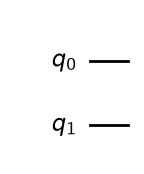

In [15]:
from qiskit import QuantumCircuit

# Prepares |00>
qc_00 = QuantumCircuit(2)
qc_00.draw('mpl')


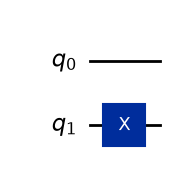

In [16]:
# Prepares |01>
qc_01 = QuantumCircuit(2)
qc_01.x(1)
qc_01.draw('mpl')

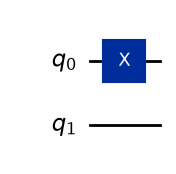

In [17]:
# Prepares |10>
qc_10 = QuantumCircuit(2)
qc_10.x(0)
qc_10.draw('mpl')

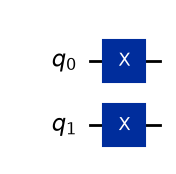

In [18]:
# Prepares |11>
qc_11 = QuantumCircuit(2)
qc_11.x(0)
qc_11.x(1)
qc_11.draw('mpl')

## Measuring Pauli terms to obtain the expectation values of operators

The qubit Hamiltonian is a sum $H_{\mathrm{qubit}}=\sum_k c_k P_k$ of Pauli strings. Each term is measured separately after rotating its qubits into the computational ($Z$) basis: a Hadamard maps an $X$ measurement to a $Z$ measurement, while the $R_x(\pi/2)$ rotation used here maps the chosen $Y$ convention to $Z$. For a measured bit string $b$, the Pauli eigenvalue is its parity, $(-1)^{\sum_{q\in P_k} b_q}$.


In [19]:
from qiskit.primitives import StatevectorSampler

def get_energy(circuit):
    energy = 0.0
    for op, coeff in H_qubit.terms.items():

        qc_meas = circuit.copy()

        # set measurement basis
        for qi, pauli in op:
            if pauli == "X":
                qc_meas.h(qi)
            if pauli == "Y":
                qc_meas.rx(np.pi / 2, qi)

        qc_meas.measure_all()

        # Sample
        sampler = StatevectorSampler()

        result = sampler.run([qc_meas], shots=1000000).result()
        counts = result[0].data.meas.get_counts()

        shots = sum(counts.values())

        for bitstring, count in counts.items():

            parity = 1

            for qi, pauli in op:
                if bitstring[::-1][qi] == "1":
                    parity *= -1

            energy += parity * count / shots * coeff
    return energy.real

print('Circuit energy 00', get_energy(qc_00))
print('Circuit energy 01', get_energy(qc_01))
print('Circuit energy 10', get_energy(qc_10))
print('Circuit energy 11', get_energy(qc_11))


Circuit energy 00 -1.116659641642317
Circuit energy 01 -0.34952012931722515
Circuit energy 10 -0.3494512693416593
Circuit energy 11 0.4624271502002244


Since we know that the ground state (singlet) is a combination of $|00>$ and $|11>$ we can prepare a circuit that encodes this superposition as a function of a parameter `theta`.

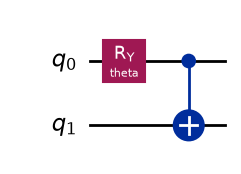

In [20]:
from qiskit.circuit import Parameter
theta = Parameter('theta')
qc_00_11 = QuantumCircuit(2)
qc_00_11.ry(theta, 0)
qc_00_11.cx(0, 1)
qc_00_11.draw('mpl')

-1.57 -0.50836159
-1.22 -0.76812185
-0.87 -0.97288272
-0.52 -1.10122237
-0.17 -1.13634857
+0.17 -1.07345983
+0.52 -0.92075529
+0.87 -0.69561563
+1.22 -0.42714189
+1.57 -0.14704781


Text(0, 0.5, 'Energy [Ha]')

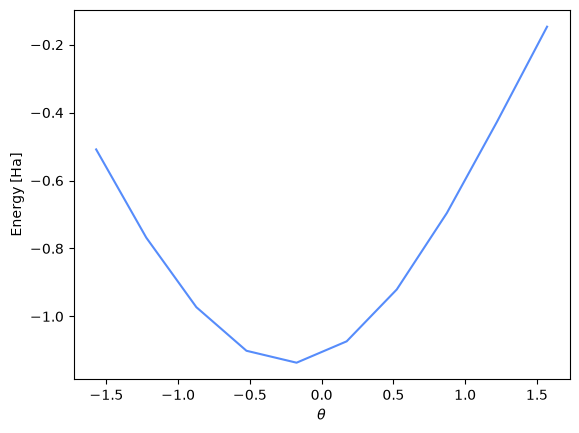

In [21]:
energies = []
angles = []
for theta in np.linspace(-np.pi/2, np.pi/2, 10):
    qc = qc_00_11.assign_parameters([theta])
    energy = get_energy(qc)
    print('{:+3.2f} {:10.8f}'.format(theta, energy))
    angles.append(theta)
    energies.append(energy)

import matplotlib.pyplot as plt
plt.plot(angles, energies)
plt.xlabel(r'$\theta$')
plt.ylabel('Energy [Ha]')